# BacMotionAI - Walkthrough

**Goal:** given the (x, y) path of one bacterium, predict which chemical condition it swam in
(`none`, `attractant`, `repellent`, `antibiotic`).

This notebook is a short, readable tour of the pipeline. The full, reproducible version lives in `scripts/`.

**Pipeline:** simulate data -> extract features -> EDA -> baselines -> train models -> evaluate -> error analysis

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

from src.data import load_dataset, split_data
from src.features import FEATURE_COLS
from src.models import CLASS_NAMES

df = load_dataset()
print("Shape:", df.shape)
print("Missing values:", int(df[FEATURE_COLS].isna().sum().sum()))
df.head()

Shape: (2400, 15)
Missing values: 0


,mean_speed,std_speed,cv_speed,straightness,mean_turn_angle,turn_bias,persistence_1s,reorient_count,mean_alignment,near_wall_frac,wall_contact_frac,chemical,channel_width,hydro,seed
0,21.688695,0.970047,0.044726,0.437039,0.077717,-0.009413,0.471646,1,0.645255,0.400000,0.093333,none,10,False,0
1,21.481289,1.431203,0.066626,0.011365,0.086866,-0.013192,0.237466,1,0.542167,0.365000,0.111667,none,10,False,1
2,19.570425,0.215023,0.010987,0.019859,0.068016,-0.007795,0.170350,3,0.902621,0.125000,0.040000,none,10,False,2
3,21.723938,0.661902,0.030469,0.211410,0.079258,0.008512,0.322119,2,0.671506,0.298333,0.103333,none,10,False,3
4,19.873653,1.424461,0.071676,0.080224,0.094300,0.014043,0.562187,0,0.299517,0.323333,0.105000,none,10,False,4


## 1. Data

Each row = one simulated bacterium (600 steps = 6 seconds). The dataset is perfectly balanced, so accuracy is a fair metric, but I still report macro-F1.

In [2]:
df["chemical"].value_counts()

chemical
none          600
attractant    600
repellent     600
antibiotic    600
Name: count, dtype: int64

## 2. Exploratory analysis

Which features differ between the conditions?

In [3]:
df.groupby("chemical")[FEATURE_COLS].mean().round(3).T

chemical,antibiotic,attractant,none,repellent
mean_speed,10.542,22.940,20.453,18.402
std_speed,0.195,0.636,0.549,0.463
cv_speed,0.018,0.027,0.027,0.025
straightness,0.370,0.521,0.454,0.444
mean_turn_angle,0.096,0.053,0.065,0.074
turn_bias,-0.000,0.002,0.000,-0.002
persistence_1s,0.197,0.452,0.344,0.331
reorient_count,3.612,1.062,1.820,1.843
mean_alignment,0.689,0.727,0.704,0.706
near_wall_frac,0.358,0.409,0.384,0.382


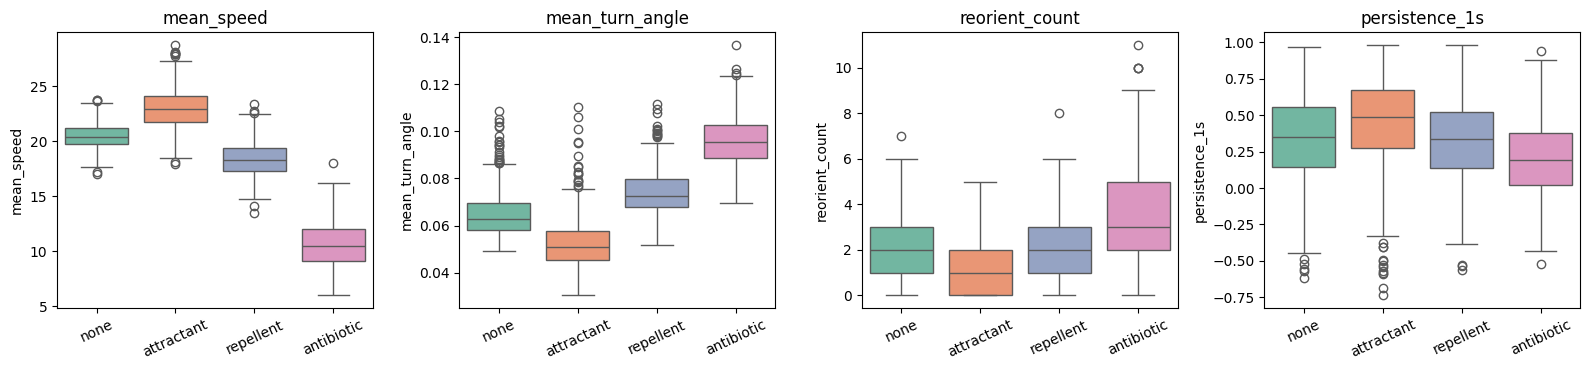

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, ["mean_speed", "mean_turn_angle", "reorient_count", "persistence_1s"]):
    sns.boxplot(data=df, x="chemical", y=col, hue="chemical", order=CLASS_NAMES, hue_order=CLASS_NAMES,
                palette="Set2", legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Observations**
- `mean_speed` separates *antibiotic* (slow) and *attractant* (fast) well, but *none* and *repellent* overlap.
- `mean_turn_angle` and `reorient_count` add extra information: antibiotic cells turn more, attractant cells turn less.
- `std_speed` and `cv_speed` are highly correlated (r = 0.94) - one of them is nearly redundant.

## 3. Split and baselines

Stratified 80/20 split. The test set stays untouched until the final evaluation. Baselines tell me how much the ML model really adds.

In [5]:
X_train, X_test, y_train, y_test, df_test = split_data(df)
print(len(X_train), "train rows |", len(X_test), "test rows")

SPEED = ["mean_speed", "std_speed", "cv_speed"]
rows = []
for name, clf, cols in [
    ("Decision tree depth 3 - mean_speed only", DecisionTreeClassifier(max_depth=3, random_state=42), ["mean_speed"]),
    ("Logistic Regression - speed features only", Pipeline([("s", StandardScaler()), ("c", LogisticRegression(max_iter=2000))]), SPEED),
    ("Logistic Regression - all 11 features", Pipeline([("s", StandardScaler()), ("c", LogisticRegression(max_iter=2000))]), FEATURE_COLS),
]:
    clf.fit(X_train[cols], y_train); p = clf.predict(X_test[cols])
    rows.append({"model": name, "accuracy": accuracy_score(y_test, p), "macro_f1": f1_score(y_test, p, average="macro")})
pd.DataFrame(rows).round(3)

1920 train rows | 480 test rows


,model,accuracy,macro_f1
0,Decision tree depth 3 - mean_speed only,0.788,0.789
1,Logistic Regression - speed features only,0.808,0.809
2,Logistic Regression - all 11 features,0.858,0.858


Speed alone already gives ~80%. Adding the path-shape and turning features lifts a simple Logistic Regression by about five points - that is the value of the feature engineering.

## 4. Models with cross-validation

Scaling is inside the `Pipeline`, so it is re-fitted on each CV fold (no leakage). Hyper-parameters here are the ones found by `scripts/train.py`.

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=10, max_iter=2000))]),
    "Random Forest": Pipeline([("scaler", StandardScaler()), ("clf", RandomForestClassifier(n_estimators=200, random_state=42))]),
}
rows = []
for name, m in models.items():
    cvs = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro")
    m.fit(X_train, y_train); p = m.predict(X_test)
    rows.append({"model": name, "cv_macro_f1": f"{cvs.mean():.3f} +/- {cvs.std():.3f}",
                 "train_acc": accuracy_score(y_train, m.predict(X_train)),
                 "test_acc": accuracy_score(y_test, p), "test_macro_f1": f1_score(y_test, p, average="macro")})
pd.DataFrame(rows).round(3)

,model,cv_macro_f1,train_acc,test_acc,test_macro_f1
0,Logistic Regression,0.853 +/- 0.018,0.862,0.858,0.858
1,Random Forest,0.884 +/- 0.021,1.000,0.873,0.873


The Random Forest reaches 100% train accuracy but ~87% test accuracy: it **overfits**, though test ≈ CV score, so the estimate is still honest. Logistic Regression has almost no train-test gap but is slightly less accurate.

## 5. Evaluation of the Random Forest

              precision    recall  f1-score   support

        none      0.752     0.783     0.767       120
  attractant      0.921     0.875     0.897       120
   repellent      0.847     0.833     0.840       120
  antibiotic      0.976     1.000     0.988       120

    accuracy                          0.873       480
   macro avg      0.874     0.873     0.873       480
weighted avg      0.874     0.873     0.873       480



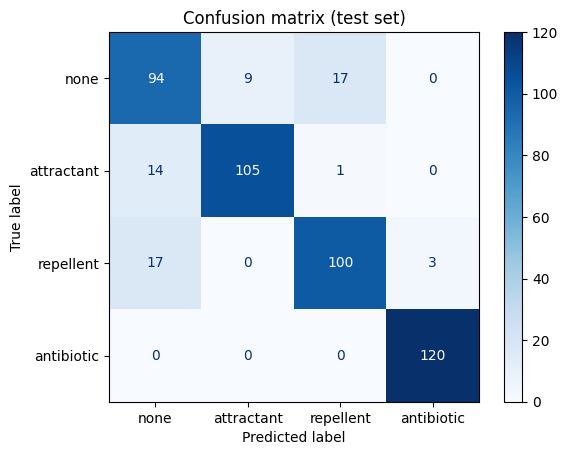

In [7]:
rf = models["Random Forest"]
pred = rf.predict(X_test)
print(classification_report(y_test, pred, labels=CLASS_NAMES, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CLASS_NAMES, cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

Antibiotic is almost perfectly detected (it is much slower). Most mistakes are between `none` and `repellent`, whose speeds overlap.

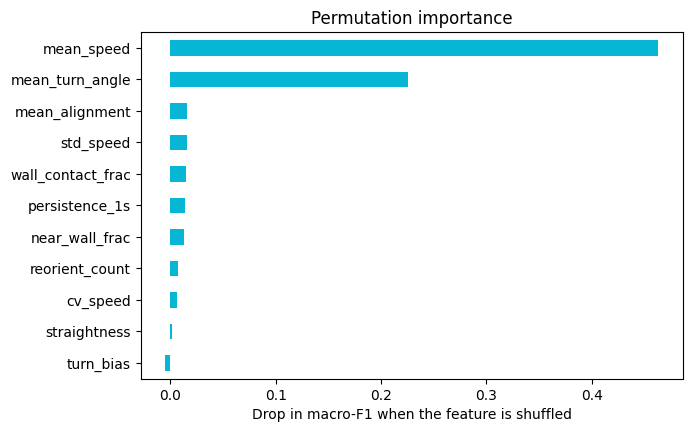

In [8]:
perm = permutation_importance(rf, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=42)
imp = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values()
imp.plot.barh(figsize=(7, 4.5), color="#06B6D4")
plt.xlabel("Drop in macro-F1 when the feature is shuffled"); plt.title("Permutation importance"); plt.show()

## 6. Error analysis

In [9]:
ea = df_test.assign(correct=(pred == y_test.values))
print(ea.groupby("channel_width")["correct"].mean().round(3).to_string())
print()
print(ea.groupby("hydro")["correct"].mean().round(3).to_string())

channel_width
10     0.770
20     0.872
30     0.831
50     0.921
75     0.945
100    0.908

hydro
False    0.852
True     0.893


Accuracy is lowest in the narrowest channel (10 µm), where wall collisions constantly disturb the path.

## 7. Conclusions and limitations
- Test accuracy ≈ 87%, far above the 25% chance level and the ~80% speed-only baseline.
- Differences between Random Forest, Gradient Boosting and Logistic Regression are small compared with the confidence intervals (see `results/`).
- **The data is simulated**, so these numbers show how separable my simulated conditions are, not real-lab performance.
- Next steps: add channel width as an input feature, try real tracking data, and calibrate the probabilities.